# IMDB Movie Reviews Sentiment Analysis:

## _A Project by Om Satyawan Pathak_

In [1]:
#Import the required modules:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import wordcloud
import nltk

#Ignore all incoming warnings (if any):
import warnings
warnings.filterwarnings("ignore")

In [2]:
#Download the stop-words:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [3]:
from nltk.corpus import stopwords

In [4]:
#Import the dataset:
data = pd.read_csv("Movie_Review.csv")

In [5]:
data

,text,sentiment
0,"My daughter liked it but I was aghast, that a ...",neg
1,I... No words. No words can describe this. I w...,neg
2,this film is basically a poor take on the old ...,neg
3,"This is a terrible movie, and I'm not even sur...",neg
4,First of all this movie is a piece of reality ...,pos
...,...,...
995,"""Campfire Tales"" is basically made up of three...",pos
996,I just saw this film at the phoenix film festi...,pos
997,It's out of question that the real Anna Anders...,pos
998,Michelle Pfeiffer stars as a mob widow who see...,pos


In [6]:
#Check the distribution in the target variable:
data.sentiment.value_counts()

sentiment
neg    500
pos    500
Name: count, dtype: int64

In [7]:
#Check for any missing values:
data.isnull().sum()

text         0
sentiment    0
dtype: int64

In [8]:
#Check for any duplicate values:
data.duplicated().sum()

np.int64(1)

In [9]:
#Drop all duplicate values:
data.drop_duplicates(inplace=True)

In [10]:
#Check again for any duplicate values:
data.duplicated().sum()

np.int64(0)

In [11]:
#Preprocess the text attribute:
def clean_review(review):
    str = ' '.join(word for word in review.split() if word.lower() not in stopwords.words('english'))
    return str
data['text'] = data['text'].apply(clean_review)

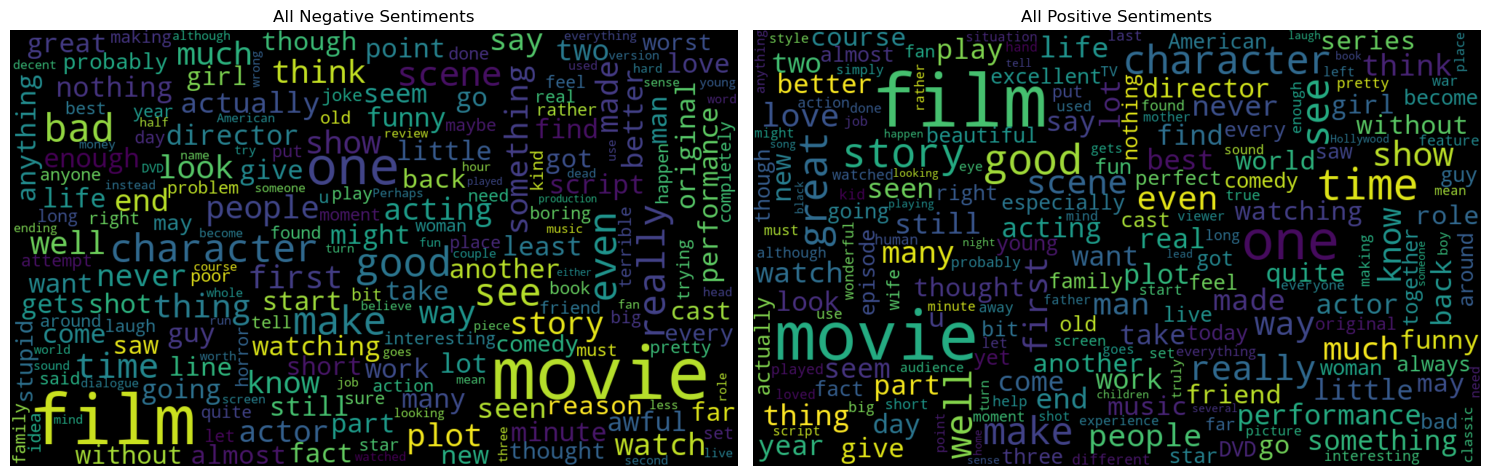

In [12]:
#Check for the most frequent words:
from wordcloud import WordCloud

reviews_neg = ' '.join(word for word in data['text'][data['sentiment'] == 'neg'].astype(str))
wordcloud_neg = WordCloud(height=600, width=1000, max_font_size=100).generate(reviews_neg)

reviews_pos = ' '.join(word for word in data['text'][data['sentiment'] == 'pos'].astype(str))
wordcloud_pos = WordCloud(height=600, width=1000, max_font_size=100).generate(reviews_pos)


plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.imshow(wordcloud_neg, interpolation='bilinear')
plt.title('All Negative Sentiments')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(wordcloud_pos, interpolation='bilinear')
plt.title('All Positive Sentiments')
plt.axis('off')

plt.tight_layout()
plt.show()

In [13]:
#Convert the reviews to numerical format:

from sklearn.feature_extraction.text import TfidfVectorizer
cv = TfidfVectorizer(max_features=2500,stop_words="english")
reviews = cv.fit_transform(data['text']).toarray()

In [14]:
#Convert the sentiments to numerical format:
data['sentiment'] = data['sentiment'].replace(['pos','neg'],[1,0])

In [15]:
data['sentiment'].value_counts()

sentiment
1    500
0    499
Name: count, dtype: int64

In [16]:
from sklearn.model_selection import train_test_split, cross_validate, KFold

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier , ExtraTreesClassifier
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier


from sklearn.metrics import classification_report , confusion_matrix

In [17]:
X = reviews
y = data["sentiment"]

X_train, X_test , y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    "Logistic Regression":LogisticRegression(max_iter=1000,random_state=42),
    "Decision-Tree Classifier":DecisionTreeClassifier(max_depth=3,random_state=42),
    "AdaBoost Classifier":AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=6),
        n_estimators=200,
        learning_rate=0.8,
        random_state=42),
    "Extra-Trees Classifier":ExtraTreesClassifier(
        n_estimators=130, max_depth=4, n_jobs=-1, random_state=42
    ),
    "XGBoost Classifier":XGBClassifier(
        n_estimators=300,
        learning_rate=0.1,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        tree_method="hist",
        eval_metric="logloss"
    ),
    "KNN Classifier":KNeighborsClassifier(n_neighbors=8, n_jobs=-1)
}

In [18]:
kf = KFold(n_splits=5,shuffle=True,random_state=42)
scoring = ["accuracy","f1_weighted"]

results=[]

for name,model in models.items():
    print(f"{name} is running .......")
    cv_results = cross_validate(model,X_train,y_train,cv=kf,scoring=scoring,n_jobs=-1)

    results.append({
        "Model":name,
        "CV Accuracy":round(np.mean(cv_results["test_accuracy"]),4),
        "CV F1 Score":round(np.mean(cv_results["test_f1_weighted"]),4)
    })

results_df = pd.DataFrame(results).sort_values(by="CV Accuracy",ascending=False).reset_index(drop=True)



display(results_df)

Logistic Regression is running .......
Decision-Tree Classifier is running .......
AdaBoost Classifier is running .......
Extra-Trees Classifier is running .......
XGBoost Classifier is running .......
KNN Classifier is running .......


,Model,CV Accuracy,CV F1 Score
0,Logistic Regression,0.7922,0.7925
1,AdaBoost Classifier,0.7434,0.7436
2,XGBoost Classifier,0.7421,0.7425
3,Extra-Trees Classifier,0.7194,0.7051
4,KNN Classifier,0.6821,0.6732
5,Decision-Tree Classifier,0.6196,0.5857


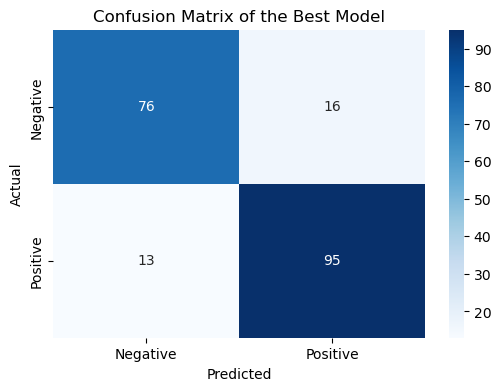

Classification Report of the best model:
              precision    recall  f1-score   support

    Positive       0.85      0.83      0.84        92
    Negative       0.86      0.88      0.87       108

    accuracy                           0.85       200
   macro avg       0.85      0.85      0.85       200
weighted avg       0.85      0.85      0.85       200



In [19]:
#Evaluate the best model (i.e. Logistic Regression) on the test set:
best_model = models["Logistic Regression"]
best_model.fit(X_train,y_train)

y_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test,y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix of the Best Model")
plt.show()
print("Classification Report of the best model:")
print(classification_report(y_test, y_pred, target_names=["Positive", "Negative"]))

In [20]:
#Export this model and the vectorizer:
import pickle as pk
pk.dump(best_model,open("movie_review_sentimentPredictor.pkl","wb"))
pk.dump(cv,open("tfidf_vectorizer.pkl","wb"))

In [21]:
with open("movie_review_sentimentPredictor.pkl", "rb") as file:
    model = pk.load(file)

with open("tfidf_vectorizer.pkl", "rb") as file:
    cv = pk.load(file)

review = input("Enter a movie review: ")

review_vector = cv.transform([review]).toarray()
prediction = model.predict(review_vector)


if prediction[0]==1:
    print("Positive Review")
else:
    print("Negative Review")

Enter a movie review:  It is a aweful movie.


Negative Review


In [22]:
review = input("Enter a movie review: ")

review_vector = cv.transform([review]).toarray()
prediction = model.predict(review_vector)


if prediction[0]==1:
    print("Positive Review")
else:
    print("Negative Review")

Enter a movie review:  It is not a aweful movie.


Negative Review


In [23]:
review = input("Enter a movie review: ")

review_vector = cv.transform([review]).toarray()
prediction = model.predict(review_vector)


if prediction[0]==1:
    print("Positive Review")
else:
    print("Negative Review")

Enter a movie review:  It is an awesome movie.


Positive Review


In [24]:
review = input("Enter a movie review: ")

review_vector = cv.transform([review]).toarray()
prediction = model.predict(review_vector)


if prediction[0]==1:
    print("Positive Review")
else:
    print("Negative Review")

Enter a movie review:  This movie is amazing


Positive Review


In [25]:
review = input("Enter a movie review: ")

review_vector = cv.transform([review]).toarray()
prediction = model.predict(review_vector)


if prediction[0]==1:
    print("Positive Review")
else:
    print("Negative Review")

Enter a movie review:  This movie is not good.


Negative Review
